# Lab Sheet 04

Harsh Saini | Roll 253028036

MCA III Semester, Session 2026-2027

Run all cells in order from this folder. Outputs below are captured from execution, not typed examples. See README for dataset sources.

## Common setup
Run once before Program 1.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Run this file or notebook from the practicals folder.
DATA = Path("datasets")
OUT = Path("outputs") / "lab_04"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 78)
pd.set_option("display.max_columns", 8)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
np.set_printoptions(precision=3, suppress=True)
sns.set_theme(style="whitegrid", font_scale=0.9)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=160)
    plt.show()

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram


## Program 01: Load a dataset suitable for clustering using the Pandas library.

**Procedure:** Load the Iris numerical feature CSV.

In [2]:
try:
    data = pd.read_csv(DATA / "iris.csv")
except (FileNotFoundError, pd.errors.ParserError) as error:
    raise RuntimeError("Check datasets/iris.csv") from error
print("Iris feature dataset:", data.shape)
print("Missing values:", data.isna().sum().sum())


Iris feature dataset: (150, 4)
Missing values: 0


**Observation:** Only flower measurements are loaded; species labels are excluded from clustering.

## Program 02: Display the first and last five records of the dataset.

**Procedure:** Display the first and last five records.

In [3]:
print("First five:")
print(data.head())
print("Last five:")
print(data.tail())


First five:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0              5.100             3.500              1.400             0.200
1              4.900             3.000              1.400             0.200
2              4.700             3.200              1.300             0.200
3              4.600             3.100              1.500             0.200
4              5.000             3.600              1.400             0.200
Last five:
     sepal length (cm)  sepal width (cm)  petal length (cm)  \
145              6.700             3.000              5.200   
146              6.300             2.500              5.000   
147              6.500             3.000              5.200   
148              6.200             3.400              5.400   
149              5.900             3.000              5.100   

     petal width (cm)  
145             2.300  
146             1.900  
147             2.000  
148             2.300  
149             1.800 

**Observation:** The dataset has four measurement columns.

## Program 03: Explore dataset information, summary statistics, and data types.

**Procedure:** Inspect structure, types, and descriptive statistics.

In [4]:
data.info()
print("Data types:")
print(data.dtypes)
print("Summary:")
print(data.describe().round(2))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object
Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count            150.000           150.000            150.000   
mean               5.840             3.060              3.760   
std                0.830             0.440              1.770   
min                4.300             2.000              1.000   
25%                5.100             2.800              1.600   
50%                5.800   

**Observation:** Clustering uses complete numeric data in this experiment.

## Program 04: Select relevant numerical features for clustering.

**Procedure:** Select numerical columns for clustering.

In [5]:
X = data.select_dtypes(include="number").copy()
print("Selected:", X.columns.tolist())
print("Shape:", X.shape)


Selected: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Shape: (150, 4)


**Observation:** All four flower measurements are numerical and selected.

## Program 05: Standardize the dataset before clustering using StandardScaler.

**Procedure:** Fit StandardScaler to the exploratory dataset and transform the features.

In [6]:
scaler = StandardScaler()
scaled = scaler.fit_transform(X)
print("First three standardized rows:")
print(scaled[:3])
print("Feature means:", scaled.mean(axis=0).round(3))


First three standardized rows:
[[-0.901  1.019 -1.34  -1.315]
 [-1.143 -0.132 -1.34  -1.315]
 [-1.385  0.328 -1.397 -1.315]]
Feature means: [-0. -0. -0. -0.]


**Observation:** Standardization prevents the raw measurement scales from dominating distance calculations.

## Program 06: Implement the K-Means clustering algorithm.

**Procedure:** Initialize K-Means with a fixed seed and fit standardized features.

In [7]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans.fit(scaled)
print("Model:", kmeans)
print("Inertia:", round(kmeans.inertia_, 3))


Model: KMeans(n_clusters=3, n_init=10, random_state=42)
Inertia: 139.82


**Observation:** K-Means minimizes within-cluster squared distances.

## Program 07: Apply K-Means clustering with K = 2 clusters.

**Procedure:** Fit K-Means with K=2 and calculate the silhouette score.

In [8]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=42)
labels2 = km2.fit_predict(scaled)
print("Cluster counts:", np.bincount(labels2))
print("Silhouette:", round(silhouette_score(scaled, labels2), 3))


Cluster counts: [100  50]
Silhouette: 0.582


**Observation:** Two clusters summarize the measurements into two groups.

## Program 08: Apply K-Means clustering with K = 3 clusters.

**Procedure:** Inspect the labels from the K=3 fit.

In [9]:
labels3 = kmeans.labels_
print("Cluster counts:", np.bincount(labels3))
print("Silhouette:", round(silhouette_score(scaled, labels3), 3))


Cluster counts: [53 50 47]
Silhouette: 0.46


**Observation:** Cluster numbers are arbitrary IDs and are not species names.

## Program 09: Apply K-Means clustering with different values of K and compare the results.

**Procedure:** Fit K=2 through 6 and compare inertia and silhouette.

In [10]:
k_results = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(scaled)
    k_results.append({"K": k, "inertia": model.inertia_,
                      "silhouette": silhouette_score(scaled, labels)})
k_table = pd.DataFrame(k_results)
print(k_table)


   K  inertia  silhouette
0  2  222.362       0.582
1  3  139.820       0.460
2  4  114.093       0.387
3  5   90.928       0.346
4  6   81.544       0.317


**Observation:** Inertia falls as K increases; silhouette need not improve.

## Program 10: Determine the optimal number of clusters using the Elbow Method.

**Procedure:** Plot inertia for K=1 through 8 and inspect where improvement slows.

The bend suggests a small K; inspect K=2 and K=3.


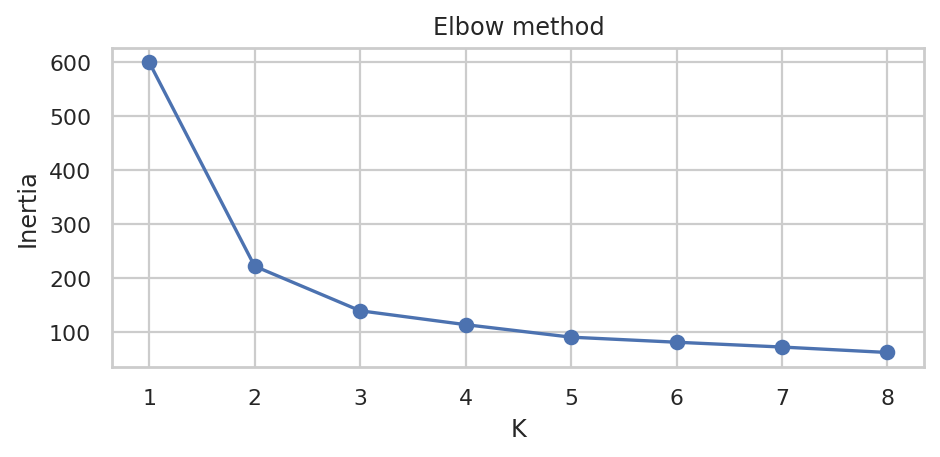

In [11]:
elbow_values = []
for k in range(1, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(scaled)
    elbow_values.append(model.inertia_)
plt.figure(figsize=(6, 3))
plt.plot(range(1, 9), elbow_values, marker="o")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title("Elbow method")
save_plot("10_elbow")
print("The bend suggests a small K; inspect K=2 and K=3.")


**Observation:** The elbow is a visual heuristic; it does not prove one unique optimal K.

## Program 11: Visualize clusters using a scatter plot.

**Procedure:** Plot petal length and width, coloured by cluster label.

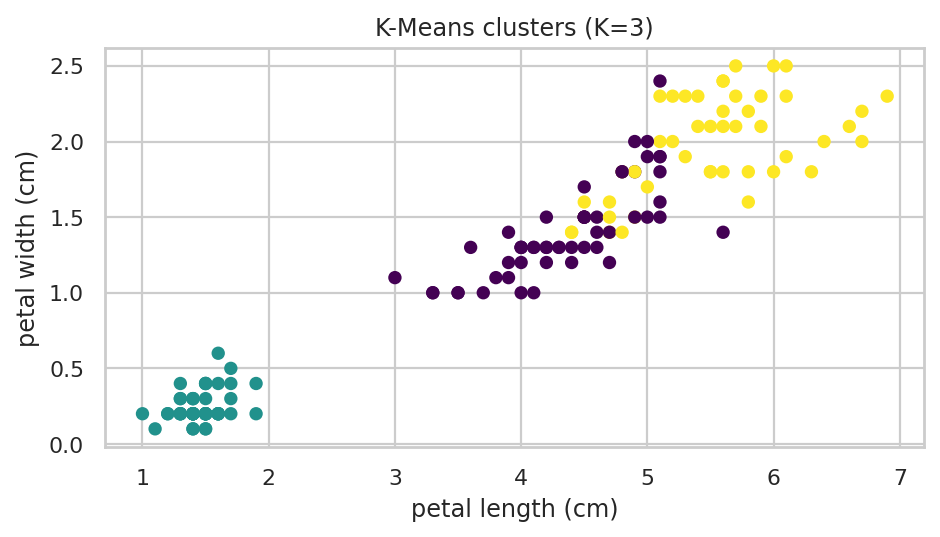

In [12]:
plt.figure(figsize=(6, 3.5))
plt.scatter(X.iloc[:, 2], X.iloc[:, 3], c=labels3,
            cmap="viridis", s=25)
plt.xlabel(X.columns[2])
plt.ylabel(X.columns[3])
plt.title("K-Means clusters (K=3)")
save_plot("11_kmeans_scatter")


**Observation:** This is a two-feature view of a clustering fitted with four features.

## Program 12: Display the cluster centroids obtained from the K-Means algorithm.

**Procedure:** Read cluster centers and invert the standardization.

In [13]:
centroids = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=X.columns)
print("Centroids in original units:")
print(centroids)


Centroids in original units:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0              5.802             2.674              4.370             1.413
1              5.006             3.428              1.462             0.246
2              6.781             3.096              5.511             1.972


**Observation:** Inverse transformation restores centroids to centimetres.

## Program 13: Assign cluster labels to the original dataset.

**Procedure:** Add K-Means labels as a new column.

In [14]:
clustered = data.copy()
clustered["cluster"] = labels3
print(clustered.head(8))
print(clustered["cluster"].value_counts().sort_index())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0              5.100             3.500              1.400             0.200   
1              4.900             3.000              1.400             0.200   
2              4.700             3.200              1.300             0.200   
3              4.600             3.100              1.500             0.200   
4              5.000             3.600              1.400             0.200   
5              5.400             3.900              1.700             0.400   
6              4.600             3.400              1.400             0.300   
7              5.000             3.400              1.500             0.200   

   cluster  
0        1  
1        1  
2        1  
3        1  
4        1  
5        1  
6        1  
7        1  
cluster
0    53
1    50
2    47
Name: count, dtype: int64


**Observation:** The original observations now carry their assigned cluster ID.

## Program 14: Compare clustering results before and after feature scaling.

**Procedure:** Fit raw-feature K-Means and compare its partition with the scaled fit.

In [15]:
raw_model = KMeans(n_clusters=3, n_init=10, random_state=42)
raw_labels = raw_model.fit_predict(X)
print("Raw-space silhouette:", round(
    silhouette_score(X, raw_labels), 3))
print("Scaled-space silhouette:", round(
    silhouette_score(scaled, labels3), 3))
print("Partition agreement (ARI):", round(
    adjusted_rand_score(raw_labels, labels3), 3))


Raw-space silhouette: 0.553
Scaled-space silhouette: 0.46
Partition agreement (ARI): 0.804


**Observation:** Scores use different distance spaces, so they are descriptive rather than a direct ranking. ARI compares the actual partitions.

## Program 15: Implement Agglomerative Hierarchical Clustering.

**Procedure:** Fit the default Ward hierarchical model to standardized features.

In [16]:
hierarchical = AgglomerativeClustering(n_clusters=3)
hier_labels = hierarchical.fit_predict(scaled)
print("Cluster counts:", np.bincount(hier_labels))
print("Silhouette:", round(silhouette_score(scaled, hier_labels), 3))


Cluster counts: [71 49 30]
Silhouette: 0.447


**Observation:** Agglomerative clustering starts from individual observations and merges clusters.

## Program 16: Generate a dendrogram using the SciPy library.

**Procedure:** Compute Ward linkage and draw a dendrogram.

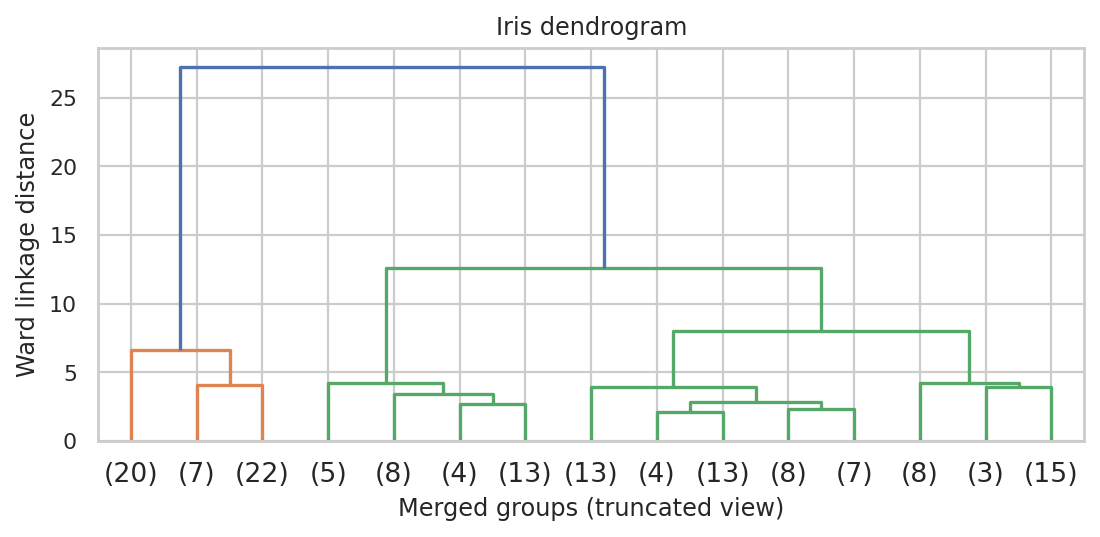

In [17]:
linkage_matrix = linkage(scaled, method="ward")
plt.figure(figsize=(7, 3.5))
dendrogram(linkage_matrix, truncate_mode="lastp", p=15,
           show_leaf_counts=True)
plt.xlabel("Merged groups (truncated view)")
plt.ylabel("Ward linkage distance")
plt.title("Iris dendrogram")
save_plot("16_dendrogram")


**Observation:** The truncated dendrogram displays the last 15 merged groups for readability.

## Program 17: Apply Hierarchical Clustering using Ward linkage.

**Procedure:** Apply Ward linkage with three clusters.

In [18]:
ward = AgglomerativeClustering(n_clusters=3, linkage="ward")
ward_labels = ward.fit_predict(scaled)
print("Ward silhouette:", round(
    silhouette_score(scaled, ward_labels), 3))


Ward silhouette: 0.447


**Observation:** Ward linkage selects merges that minimize increased within-cluster variance.

## Program 18: Apply Hierarchical Clustering using Complete linkage.

**Procedure:** Fit a complete-linkage model to the same scaled dataset.

In [19]:
complete = AgglomerativeClustering(n_clusters=3,
                                   linkage="complete")
complete_labels = complete.fit_predict(scaled)
print("Complete silhouette:", round(
    silhouette_score(scaled, complete_labels), 3))
print("Counts:", np.bincount(complete_labels))


Complete silhouette: 0.45
Counts: [77 49 24]


**Observation:** Complete linkage uses the largest pairwise distance between two clusters.

## Program 19: Compare different linkage methods.

**Procedure:** Fit four linkage methods at the same cluster count and compare scores.

In [20]:
linkage_results = []
for method in ["ward", "complete", "average", "single"]:
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(scaled)
    linkage_results.append({"linkage": method,
        "silhouette": silhouette_score(scaled, labels),
        "smallest_cluster": np.bincount(labels).min()})
print(pd.DataFrame(linkage_results))


    linkage  silhouette  smallest_cluster
0      ward       0.447                30
1  complete       0.450                24
2   average       0.480                 3
3    single       0.505                 1


**Observation:** Different linkage rules can produce very different cluster sizes.

## Program 20: Visualize Hierarchical Clustering results.

**Procedure:** Plot petal measurements with Ward labels as colours.

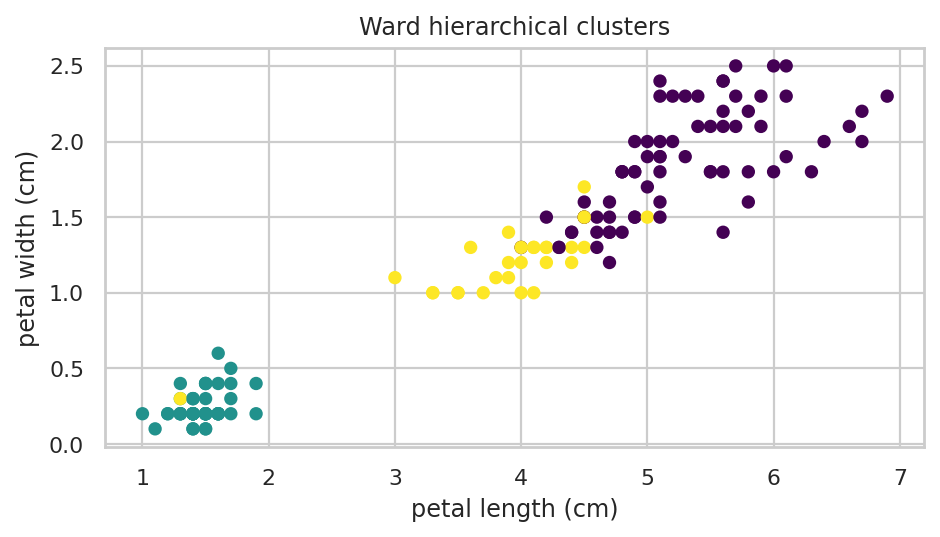

In [21]:
plt.figure(figsize=(6, 3.5))
plt.scatter(X.iloc[:, 2], X.iloc[:, 3], c=ward_labels,
            cmap="viridis", s=25)
plt.xlabel(X.columns[2])
plt.ylabel(X.columns[3])
plt.title("Ward hierarchical clusters")
save_plot("20_hierarchical")


**Observation:** The plot shows Ward labels over two original measurements.

## Program 21: Compare Hierarchical Clustering with K-Means clustering.

**Procedure:** Compare silhouette and partition agreement for K-Means and Ward.

In [22]:
cluster_comparison = pd.DataFrame({
    "method": ["K-Means", "Ward"],
    "silhouette": [silhouette_score(scaled, labels3),
                   silhouette_score(scaled, ward_labels)]})
print(cluster_comparison)
print("Partition agreement (ARI):", round(
    adjusted_rand_score(labels3, ward_labels), 3))


    method  silhouette
0  K-Means       0.460
1     Ward       0.447
Partition agreement (ARI): 0.626


**Observation:** Both algorithms are evaluated on the same standardized distance space.

## Program 22: Apply Principal Component Analysis (PCA) to reduce dataset dimensions.

**Procedure:** Fit PCA on standardized features and inspect the component variances.

In [23]:
full_pca = PCA().fit(scaled)
print("Original dimensions:", scaled.shape[1])
print("All explained variance ratios:",
      full_pca.explained_variance_ratio_.round(4))


Original dimensions: 4
All explained variance ratios: [0.73  0.229 0.037 0.005]


**Observation:** PCA orders orthogonal directions by the variance they explain.

## Program 23: Reduce a dataset from multiple features to two principal components.

**Procedure:** Project the four features onto the first two components.

In [24]:
pca2 = PCA(n_components=2)
reduced = pca2.fit_transform(scaled)
print("Reduced shape:", reduced.shape)
print("First five rows:")
print(reduced[:5])


Reduced shape: (150, 2)
First five rows:
[[-2.265  0.48 ]
 [-2.081 -0.674]
 [-2.364 -0.342]
 [-2.299 -0.597]
 [-2.39   0.647]]


**Observation:** Each sample is now represented by two principal-component scores.

## Program 24: Visualize the transformed data using a two-dimensional scatter plot.

**Procedure:** Plot the two principal components.

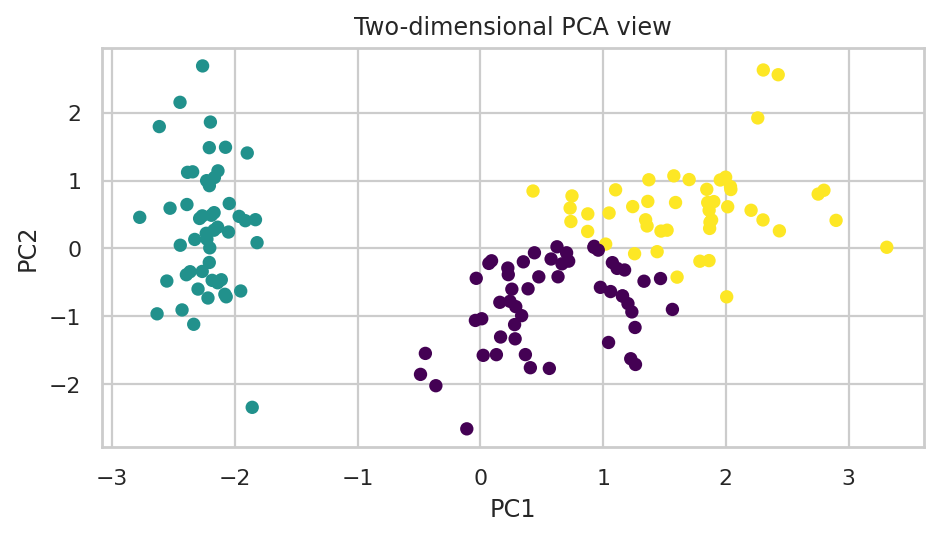

In [25]:
plt.figure(figsize=(6, 3.5))
plt.scatter(reduced[:, 0], reduced[:, 1], c=labels3,
            cmap="viridis", s=25)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Two-dimensional PCA view")
save_plot("24_pca_scatter")


**Observation:** Colours show the original four-feature K-Means labels.

## Program 25: Display the explained variance ratio of principal components.

**Procedure:** Display explained_variance_ratio_ for the two-component PCA.

In [26]:
print("PC1 and PC2 variance ratios:",
      pca2.explained_variance_ratio_.round(4))
print("Total retained variance:", round(
    pca2.explained_variance_ratio_.sum(), 4))


PC1 and PC2 variance ratios: [0.73  0.229]
Total retained variance: 0.9581


**Observation:** The variance ratios refer to standardized inputs.

## Program 26: Determine the cumulative explained variance.

**Procedure:** Cumulatively sum the variance ratios and apply a 95% threshold.

In [27]:
cumulative = np.cumsum(full_pca.explained_variance_ratio_)
print("Cumulative variance:", cumulative.round(4))
print("Components needed for at least 95% variance:",
      np.searchsorted(cumulative, 0.95) + 1)


Cumulative variance: [0.73  0.958 0.995 1.   ]
Components needed for at least 95% variance: 2


**Observation:** Cumulative explained variance helps choose how many components to retain.

## Program 27: Compare the dataset before and after dimensionality reduction.

**Procedure:** Compare shapes and reconstruct the standardized inputs from two components.

In [28]:
reconstructed = pca2.inverse_transform(reduced)
print("Before PCA:", scaled.shape)
print("After PCA:", reduced.shape)
print("Reconstruction MSE:", round(
    np.mean((scaled - reconstructed) ** 2), 5))


Before PCA: (150, 4)
After PCA: (150, 2)
Reconstruction MSE: 0.04187


**Observation:** Reducing dimensionality loses some information, measured here by reconstruction error.

## Program 28: Perform K-Means clustering on the PCA-transformed dataset.

**Procedure:** Fit three-cluster K-Means on the PCA-transformed data.

In [29]:
pca_kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
pca_labels = pca_kmeans.fit_predict(reduced)
print("PCA cluster counts:", np.bincount(pca_labels))
print("PCA-space silhouette:", round(
    silhouette_score(reduced, pca_labels), 3))


PCA cluster counts: [53 50 47]
PCA-space silhouette: 0.509


**Observation:** K-Means now uses distances between two-component projections.

## Program 29: Compare clustering performance before and after applying PCA.

**Procedure:** Compare PCA and original partitions, including a score in a common feature space.

In [30]:
print("Four-feature silhouette:", round(
    silhouette_score(scaled, labels3), 3))
print("PCA-space silhouette:", round(
    silhouette_score(reduced, pca_labels), 3))
print("PCA labels scored in original scaled space:", round(
    silhouette_score(scaled, pca_labels), 3))
print("Partition agreement (ARI):", round(
    adjusted_rand_score(labels3, pca_labels), 3))


Four-feature silhouette: 0.46
PCA-space silhouette: 0.509
PCA labels scored in original scaled space: 0.46
Partition agreement (ARI): 1.0


**Observation:** The common-space score helps distinguish partition changes from a change in distance representation.

## Program 30: Calculate the Silhouette Score for cluster evaluation.

**Procedure:** Calculate silhouette_score for the three-cluster partition.

In [31]:
score = silhouette_score(scaled, labels3)
print("K=3 silhouette:", round(score, 3))
print("Range: -1 to 1; larger usually means clearer separation.")


K=3 silhouette: 0.46
Range: -1 to 1; larger usually means clearer separation.


**Observation:** Silhouette compares within-cluster distances with the nearest alternative cluster.

## Program 31: Compare Silhouette Scores for different values of K.

**Procedure:** Compare silhouette scores over the tested cluster counts.

In [32]:
print(k_table[["K", "silhouette"]])
print("Highest silhouette among tested K:",
      int(k_table.loc[k_table["silhouette"].idxmax(), "K"]))


   K  silhouette
0  2       0.582
1  3       0.460
2  4       0.387
3  5       0.346
4  6       0.317
Highest silhouette among tested K: 2


**Observation:** The strongest silhouette need not equal the number of known Iris species.

## Program 32: Analyze the characteristics of each cluster using descriptive statistics.

**Procedure:** Group original measurements by cluster and calculate means and standard deviations.

In [33]:
print("Cluster mean measurements:")
print(clustered.groupby("cluster").mean().round(3))
print("Cluster standard deviations:")
print(clustered.groupby("cluster").std().round(3))


Cluster mean measurements:
         sepal length (cm)  sepal width (cm)  petal length (cm)  \
cluster                                                           
0                    5.802             2.674              4.370   
1                    5.006             3.428              1.462   
2                    6.781             3.096              5.511   

         petal width (cm)  
cluster                    
0                   1.413  
1                   0.246  
2                   1.972  
Cluster standard deviations:
         sepal length (cm)  sepal width (cm)  petal length (cm)  \
cluster                                                           
0                    0.405             0.254              0.560   
1                    0.352             0.379              0.174   
2                    0.491             0.262              0.638   

         petal width (cm)  
cluster                    
0                   0.311  
1                   0.105  
2                   

**Observation:** Cluster means summarize measurement patterns; no species labels were used to form them.

## Program 33: Visualize cluster distributions using pair plots or scatter plots.

**Procedure:** Draw two scatter views of the cluster distribution.

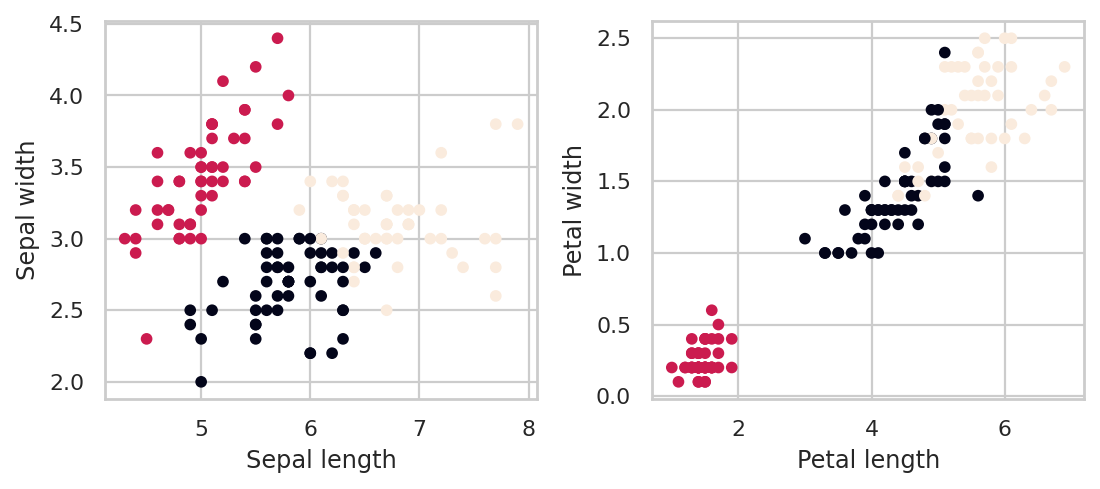

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], c=labels3, s=18)
axes[0].set_xlabel("Sepal length")
axes[0].set_ylabel("Sepal width")
axes[1].scatter(X.iloc[:, 2], X.iloc[:, 3], c=labels3, s=18)
axes[1].set_xlabel("Petal length")
axes[1].set_ylabel("Petal width")
save_plot("33_cluster_distributions")


**Observation:** Cluster separation differs between measurement pairs.

## Program 34: Save the clustered dataset as a CSV file.

**Procedure:** Export labelled observations and reload to verify the result.

In [35]:
clustered.to_csv(OUT / "iris_clustered.csv", index=False)
print("Saved: iris_clustered.csv")
print("Reloaded shape:",
      pd.read_csv(OUT / "iris_clustered.csv").shape)


Saved: iris_clustered.csv
Reloaded shape: (150, 5)


**Observation:** The saved CSV includes four measurements and one cluster column.

## Program 35: Compare the performance of K-Means and Hierarchical Clustering and summarize the findings.

**Procedure:** Summarize the measured scores and practical differences between the algorithms.

In [36]:
print(cluster_comparison)
print("K-Means: centroid-based, requires K and a seed.")
print("Ward: merge-based, can be inspected with a dendrogram.")
print("Highest score here:", cluster_comparison.loc[
    cluster_comparison["silhouette"].idxmax(), "method"])
print("These scores describe this dataset and scaling choice.")


    method  silhouette
0  K-Means       0.460
1     Ward       0.447
K-Means: centroid-based, requires K and a seed.
Ward: merge-based, can be inspected with a dendrogram.
Highest score here: K-Means
These scores describe this dataset and scaling choice.


**Observation:** Neither algorithm is universally best; the result depends on features, distances, and cluster count.